#Análisis de tienda Superstore

Ante la creciente demanda y la feroz competencia en el mercado, una gran cadena de supermercados busca determinar cómo han sido los resultados de su último año y qué es lo que mejor funciona de su negocio.

El propósito es analizar hacia qué productos, regiones, categorías y segmentos de clientes deben dirigirse o cuáles deben evitar.

Las primeras fases del proyecto fueron realizadas por medio de SQL DuckDB, obteniendo cuadros resumen y tablas consolidadas con datos y KPI's útiles para el análisis.

Por último, el proyecto se lleva un paso más allá al generar un modelo de regresión lineal que utilice la información disponible de ventas para pronósticar los resultados mensuales de los próximos periodos del año 2018. Dicha fase del proyecto se realiza con el uso de modelos estadísticos de pronóstico y se desarrolla dentro de este mismo notebook.

Flujo metodológico:

Validación y limpieza (SQL) → Resumen global 2014-2017 (SQL) → Análisis segmentado (SQL) → Recomendaciones → Pronóstico de ingresos

---

In [ ]:
#Librerías necesarias
import pandas as pd #Manejo de dataframes
import numpy as np #Cálculo matemáticos
import matplotlib.pyplot as plt #Gráficos
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf #Gráficos ACF y PACF
from sklearn.metrics import mean_absolute_error, mean_squared_error #Métricas de error
from statsmodels.tsa.holtwinters import ExponentialSmoothing #Modelo Holt-Winters
from statsmodels.tsa.stattools import adfuller, kpss #Pruebas ADF y KPSS
from statsmodels.tsa.statespace.sarimax import SARIMAX #Modelo SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox #Prueba Ljung-Box

##Base de datos a utilizar

| Variable        | Descripción                                     |
| --------------- | ----------------------------------------------- |
| `row_id`        | Identificador único de cada fila.               |
| `order_id`      | Identificador único del pedido de cada cliente. |
| `order_date`    | Fecha en que se realizó el pedido.              |
| `ship_date`     | Fecha de envío del producto.                    |
| `ship_mode`     | Modalidad de envío seleccionada por el cliente. |
| `customer_id`   | Identificador único de cada cliente.            |
| `customer_name` | Nombre del cliente.                             |
| `segment`       | Segmento al que pertenece el cliente.           |
| `country`       | País de residencia del cliente.                 |
| `city`          | Ciudad de residencia del cliente.               |
| `state`         | Estado o provincia de residencia del cliente.   |
| `postal_code`   | Código postal del cliente.                      |
| `region`        | Región a la que pertenece el cliente.           |
| `product_id`    | Identificador único del producto.               |
| `category`      | Categoría del producto solicitado.              |
| `sub_category`  | Subcategoría del producto solicitado.           |
| `product_name`  | Nombre del producto.                            |
| `sales`         | Ventas generadas por el producto.               |
| `quantity`      | Cantidad de unidades del producto.              |
| `discount`      | Descuento aplicado al pro                       |


El dataset a utilizar en este proyecto es `store_data.csv`, el cual consta de una serie 20 columnas con un total de 9,994 registros de ventas concretadas en la tienda de supermercados durante el periódo de operación comprendido entre el 01/01/2014 y 31/12/2017.

---

##Validación y limpieza del dataset

###Revisión de tipos

| column_name    | column_type | null | key | default | extra |
|----------------|-------------|------|-----|---------|-------|
| row_id         | BIGINT      | YES  |     |         |       |
| order_id       | VARCHAR     | YES  |     |         |       |
| order_date     | DATE        | YES  |     |         |       |
| ship_date      | DATE        | YES  |     |         |       |
| ship_mode      | VARCHAR     | YES  |     |         |       |
| customer_id    | VARCHAR     | YES  |     |         |       |
| customer_name  | VARCHAR     | YES  |     |         |       |
| segment        | VARCHAR     | YES  |     |         |       |
| country        | VARCHAR     | YES  |     |         |       |
| city           | VARCHAR     | YES  |     |         |       |
| state          | VARCHAR     | YES  |     |         |       |
| postal_code    | BIGINT      | YES  |     |         |       |
| region         | VARCHAR     | YES  |     |         |       |
| product_id     | VARCHAR     | YES  |     |         |       |
| category       | VARCHAR     | YES  |     |         |       |
| sub_category   | VARCHAR     | YES  |     |         |       |
| product_name   | VARCHAR     | YES  |     |         |       |
| sales          | DOUBLE      | YES  |     |         |       |
| quantity       | BIGINT      | YES  |     |         |       |
| discount       | DOUBLE      | YES  |     |         |       |
| profit         | DOUBLE      | YES  |     |         |       |

**Notas:**
- La base de datos muestra tipos de datos correctos, acertando tanto para columnas cualitativas como en columnas cuantitativas. En este segundo tipo se puede observar la correcta asignación del formato 'DATE' para las variables de fecha, el formato 'INT' para variables discretas, y el formato 'DOUBLE PRECISION' para variables continuas.



---

###Conteo de nulos

| row_id | order_id | order_date | ship_date | ship_mode | customer_id | customer_name | segment | country | city | state | postal_code | region | product_id | category | sub_category | product_name | sales | quantity | discount | profit |
|--------|----------|------------|-----------|-----------|-------------|---------------|---------|---------|------|-------|-------------|--------|------------|----------|-------------|--------------|-------|----------|----------|--------|
| 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 |

**Notas:**
- Algo que se observa en la revisión anterior es que todas las columnas admiten valores nulos, por lo que previo al uso del dataset para hacer los cálculos y análisis correspondientes, se debe de realizar un conteo de registros nulos.
- El conteo de registros nulos arrojó un resultado de 0 para las 20 columnas contenidas en la base de datos, por lo cual no hace falta llevar a cabo acciones de limpieza para este aspecto.

---

###Conteo de duplicados

| total_registros | total_unicos |
|-----------------|--------------|
| 9994            | 9994         |

**Notas:**
- Por último, el conteo de datos duplicados muestra una consistencia entre el número de registros únicos (calculado en base a la columna row_id) y el total registros del dataset.
- Después de realizar la revisión y validación, el dataset se encuentra listo para generar KPI's e insights con información validada.

---

##Análisis de resultados 2017

###Resumen global

####Anual

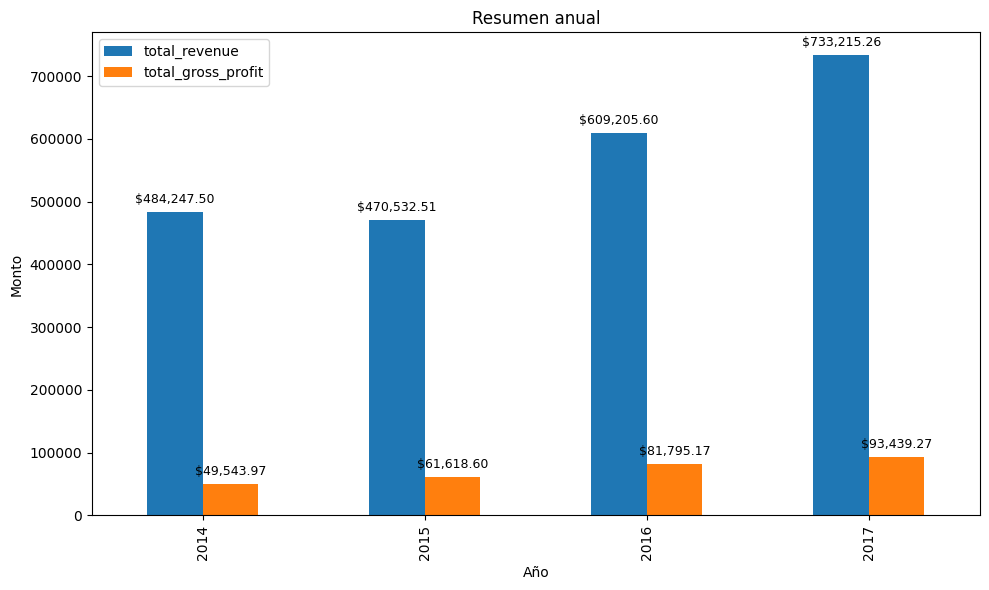

In [ ]:
#Importar dataset
anual_summary = pd.read_csv('2014-2017_summary.csv')

#Generación de gráfico
ax = anual_summary.plot(x='year', y=['total_revenue', 'total_gross_profit'],
                        kind='bar', figsize=(10, 6))

#Etiquetas del gráfico
for p in ax.patches:
    val = p.get_height()
    if val > 0:
        ax.annotate(f'${val:,.2f}',
                    (p.get_x() + p.get_width() / 2., val),
                    ha='center', va='center',
                    xytext=(0, 9),
                    textcoords='offset points',
                    fontsize=9)

plt.title('Resumen anual')
plt.xlabel('Año')
plt.ylabel('Monto')
plt.tight_layout()
plt.show()

| year | total_orders | orders_YoY_pct | total_products_sold | products_YoY_pct | total_revenue | revenue_YoY_pct | total_gross_profit | profit_YoY_pct | gross_margin_pct | margin_YoY_pct |
|------|--------------|----------------|---------------------|------------------|---------------|-----------------|--------------------|----------------|------------------|----------------|
| 2014 | 969 | | 7581 | | 484247.5 | | 49543.97 | | 10.23 | |
| 2015 | 1038 | 7.12 | 7979 | 5.25 | 470532.51 | -2.83 | 61618.6 | 24.37 | 13.1 | 28 |
| 2016 | 1315 | 26.69 | 9837 | 23.29 | 609205.6 | 29.47 | 81795.17 | 32.74 | 13.43 | 2.53 |
| 2017 | 1687 | 28.29 | 12476 | 26.83 | 733215.26 | 20.36 | 93439.27 | 14.24 | 12.74 | -5.09 |

**Notas:**

El número de órdenes y el total de productos vendidos muestra un aumento continuo año con año, con un ritmo de crecimiento exponencial, lo que muestra una señal bastante positiva en cuanto al número de transacciones en el futuro.

A pesar del aumento del 5.25% en productos vendidos en 2015, los ingresos totales mostraron una caída del 2.83%, lo que señala una baja importante en el ticket promedio de compra. Sin embargo, en años posteriores el crecimiento de los ingresos saltó por encima del 20% anual en los últimos dos años.

La utilidad bruta se ha mostrado con crecimiento contínuo, lo cual es un buen presagio para el rendimiento futuro. Sin embargo el foco debe de concentrarse en los márgenes, ya que si bien no se pueden atener las proyecciones futuras a un crecimiento en los márgenes como el que se aprecia en el año 2015, lo cierto es que el reciente decremento anual del 5.09% en los márgenes brutos de 2017 señala la necesidad de identificar qué segmentos se deberían de priorizar y cuáles se deberían de evitar para mejorar el margen.



---

####Mensual

| year | month | current_orders | orders_YoY_pct | current_products_sold | products_sold_YoY_pct | current_revenue | revenue_YoY_pct | current_profit | profit_YoY_pct | current_gross_margin_pct | margin_YoY_pct |
|------|-------|----------------|----------------|-----------------------|-----------------------|-----------------|-----------------|----------------|----------------|--------------------------|----------------|
| 2014 | 1 | 32 | | 284 | | 14236.89 | | 2450.19 | | 17.21 | |
| 2014 | 2 | 28 | | 159 | | 4519.89 | | 862.31 | | 19.08 | |
| 2014 | 3 | 71 | | 585 | | 55691.01 | | 498.73 | | 0.9 | |
| 2014 | 4 | 66 | | 536 | | 28295.34 | | 3488.84 | | 12.33 | |
| 2014 | 5 | 69 | | 466 | | 23648.29 | | 2738.71 | | 11.58 | |
| 2014 | 6 | 66 | | 521 | | 34595.13 | | 4976.52 | | 14.39 | |
| 2014 | 7 | 65 | | 550 | | 33946.39 | | -841.48 | | -2.48 | |
| 2014 | 8 | 72 | | 609 | | 27909.47 | | 5318.11 | | 19.05 | |
| 2014 | 9 | 130 | | 1000 | | 81777.35 | | 8328.1 | | 10.18 | |
| 2014 | 10 | 78 | | 573 | | 31453.39 | | 3448.26 | | 10.96 | |
| 2014 | 11 | 151 | | 1219 | | 78628.72 | | 9292.13 | | 11.82 | |
| 2014 | 12 | 141 | | 1079 | | 69545.62 | | 8983.57 | | 12.92 | |
| 2015 | 1 | 29 | -9.38 | 236 | -16.9 | 18174.08 | 27.65 | -3281.01 | -233.91 | -18.05 | -204.9 |
| 2015 | 2 | 36 | 28.57 | 239 | 50.31 | 11951.41 | 164.42 | 2813.85 | 226.32 | 23.54 | 23.41 |
| 2015 | 3 | 79 | 11.27 | 515 | -11.97 | 38726.25 | -30.46 | 9732.1 | 1851.38 | 25.13 | 2706.21 |
| 2015 | 4 | 72 | 9.09 | 543 | 1.31 | 34195.21 | 20.85 | 4187.5 | 20.03 | 12.25 | -0.68 |
| 2015 | 5 | 74 | 7.25 | 575 | 23.39 | 30131.69 | 27.42 | 4667.87 | 70.44 | 15.49 | 33.77 |
| 2015 | 6 | 68 | 3.03 | 486 | -6.72 | 24797.29 | -28.32 | 3335.56 | -32.97 | 13.45 | -6.49 |
| 2015 | 7 | 66 | 1.54 | 557 | 1.27 | 28765.32 | -15.26 | 3288.65 | -490.82 | 11.43 | -561.21 |
| 2015 | 8 | 68 | -5.56 | 598 | -1.81 | 36898.33 | 32.21 | 5355.81 | 0.71 | 14.52 | -23.82 |
| 2015 | 9 | 140 | 7.69 | 1086 | 8.6 | 64595.92 | -21.01 | 8209.16 | -1.43 | 12.71 | 24.79 |
| 2015 | 10 | 87 | 11.54 | 631 | 10.12 | 31404.92 | -0.15 | 2817.37 | -18.3 | 8.97 | -18.17 |
| 2015 | 11 | 158 | 4.64 | 1310 | 7.47 | 75972.56 | -3.38 | 12474.79 | 34.25 | 16.42 | 38.94 |
| 2015 | 12 | 161 | 14.18 | 1203 | 11.49 | 74919.52 | 7.73 | 8016.97 | -10.76 | 10.7 | -17.16 |
| 2016 | 1 | 48 | 65.52 | 358 | 51.69 | 18542.49 | 2.03 | 2824.82 | -186.1 | 15.23 | -184.39 |
| 2016 | 2 | 45 | 25 | 306 | 28.03 | 22978.82 | 92.27 | 5004.58 | 77.86 | 21.78 | -7.5 |
| 2016 | 3 | 86 | 8.86 | 579 | 12.43 | 51715.88 | 33.54 | 3611.97 | -62.89 | 6.98 | -72.21 |
| 2016 | 4 | 89 | 23.61 | 635 | 16.94 | 38750.04 | 13.32 | 2977.81 | -28.89 | 7.68 | -37.25 |
| 2016 | 5 | 108 | 45.95 | 863 | 50.09 | 56987.73 | 89.13 | 8662.15 | 85.57 | 15.2 | -1.88 |
| 2016 | 6 | 97 | 42.65 | 742 | 52.67 | 40344.53 | 62.7 | 4750.38 | 42.42 | 11.77 | -12.47 |
| 2016 | 7 | 96 | 45.45 | 758 | 36.09 | 39261.96 | 36.49 | 4432.88 | 34.79 | 11.29 | -1.24 |
| 2016 | 8 | 90 | 32.35 | 693 | 15.89 | 31115.37 | -15.67 | 2062.07 | -61.5 | 6.63 | -54.34 |
| 2016 | 9 | 192 | 37.14 | 1316 | 21.18 | 73410.02 | 13.64 | 9328.66 | 13.64 | 12.71 | -0.01 |
| 2016 | 10 | 105 | 20.69 | 767 | 21.55 | 59687.75 | 90.06 | 16243.14 | 476.54 | 27.21 | 203.35 |
| 2016 | 11 | 183 | 15.82 | 1406 | 7.33 | 79411.97 | 4.53 | 4011.41 | -67.84 | 5.05 | -69.24 |
| 2016 | 12 | 176 | 9.32 | 1414 | 17.54 | 96999.04 | 29.47 | 17885.31 | 123.09 | 18.44 | 72.31 |
| 2017 | 1 | 69 | 43.75 | 597 | 66.76 | 43971.37 | 137.14 | 7140.44 | 152.77 | 16.24 | 6.59 |
| 2017 | 2 | 53 | 17.78 | 363 | 18.63 | 20301.13 | -11.65 | 1613.87 | -67.75 | 7.95 | -63.5 |
| 2017 | 3 | 118 | 37.21 | 885 | 52.85 | 58872.35 | 13.84 | 14751.89 | 308.42 | 25.06 | 258.77 |
| 2017 | 4 | 116 | 30.34 | 733 | 15.43 | 36521.54 | -5.75 | 933.29 | -68.66 | 2.56 | -66.75 |
| 2017 | 5 | 118 | 9.26 | 887 | 2.78 | 44261.11 | -22.33 | 6342.58 | -26.78 | 14.33 | -5.72 |
| 2017 | 6 | 133 | 37.11 | 931 | 25.47 | 52981.73 | 31.32 | 8223.34 | 73.11 | 15.52 | 31.82 |
| 2017 | 7 | 111 | 15.63 | 840 | 10.82 | 45264.42 | 15.29 | 6952.62 | 56.84 | 15.36 | 36.04 |
| 2017 | 8 | 111 | 23.33 | 884 | 27.56 | 63120.89 | 102.86 | 9040.96 | 338.44 | 14.32 | 116.13 |
| 2017 | 9 | 226 | 17.71 | 1660 | 26.14 | 87866.65 | 19.69 | 10991.56 | 17.83 | 12.51 | -1.56 |
| 2017 | 10 | 147 | 40 | 1133 | 47.72 | 77776.92 | 30.31 | 9275.28 | -42.9 | 11.93 | -56.18 |
| 2017 | 11 | 261 | 42.62 | 1840 | 30.87 | 118447.83 | 49.16 | 9690.1 | 141.56 | 8.18 | 61.95 |
| 2017 | 12 | 224 | 27.27 | 1723 | 21.85 | 83829.32 | -13.58 | 8483.35 | -52.57 | 10.12 | -45.12 |

**Notas:**

Por medio de la visualización en formato mensual se puede observar el comportamiento y tendencia a una frecuencia mayor, sobre todo al contemplar una métrica de crecimiento anual que compare periodos de un mismo mes, pero en años distintos, para de esta forma realizar una comparación más justa y que no sea afecatada por la estacionalidad.

Esta tabla será utilizada posteriormente para pronosticar (en base a parámetros simples) los ingresos futuros para establecer metas de rendimiento contínuo que sirvan para evaluar el funcionamiento de las estrategias a implementar.

---

###Análisis segmentado

####Resultados por segmento de clientes

| segment | revenue_2014 | profit_2014 | margin_pct_2014 | revenue_2015 | profit_2015 | margin_pct_2015 | revenue_2016 | profit_2016 | margin_pct_2016 | revenue_2017 | profit_2017 | margin_pct_2017 |
|---------|-------------:|------------:|----------------:|-------------:|------------:|----------------:|-------------:|------------:|----------------:|-------------:|------------:|----------------:|
| Consumer | 266096.81 | 24319.85 | 9.14 | 266535.93 | 28460.17 | 10.68 | 296863.9 | 35770.95 | 12.05 | 331904.7 | 45568.24 | 13.73 |
| Corporate | 128434.87 | 13513.28 | 10.52 | 128757.31 | 20688.32 | 16.07 | 207106.36 | 30995.17 | 14.97 | 241847.82 | 26782.36 | 11.07 |
| Home Office | 89715.81 | 11710.85 | 13.05 | 75239.27 | 12470.11 | 16.57 | 105235.34 | 15029.05 | 14.28 | 159462.73 | 21088.67 | 13.22 |

**Notas:**

Históricamente el segmento de clientes de la categoría de consumo minorista ha permanecido como el que más ingresos y ganancias genera, seguido del sector corporativo y el sector "home office", los cuales compensan sus niveles de ingreso más bajos por medio de márgenes superiores.

Los tres segmentos han experimentado un crecimiento contínuo y márgenes estables a lo largo del periodo de 4 años. Destaca el sector de consumo minorista debido a que es el único segmento que ha mostrado un incremento ininterrumpido de sus márgenes.

Un comportamiento bastante llamativo para los otros dos sectores es el decremento de sus márgenes, ya que después de alcanzar su punto más alto en 2015, se ha visto una tendencia bajista que se ha sostenido hasta el punto en que los márgenes han llegado casi al mismo nivel o por debajo del nivel presentado por el segmento minorista.

---

####Resultados por región

| region | revenue_2014 | profit_2014 | margin_pct_2014 | revenue_2015 | profit_2015 | margin_pct_2015 | revenue_2016 | profit_2016 | margin_pct_2016 | revenue_2017 | profit_2017 | margin_pct_2017 |
|--------|-------------:|------------:|----------------:|-------------:|------------:|----------------:|-------------:|------------:|----------------:|-------------:|------------:|----------------:|
| West | 147883.03 | 20065.69 | 13.57 | 139966.25 | 20492.19 | 14.64 | 187480.18 | 24051.61 | 12.83 | 250128.37 | 43808.96 | 17.51 |
| East | 128680.46 | 17059.61 | 13.26 | 156332.06 | 21091.01 | 13.49 | 180685.82 | 20141.6 | 11.15 | 213082.9 | 33230.56 | 15.6 |
| Central | 103838.16 | 539.55 | 0.52 | 102874.22 | 11716.8 | 11.39 | 147429.38 | 19899.16 | 13.5 | 147098.13 | 7550.84 | 5.13 |
| South | 103845.84 | 11879.12 | 11.44 | 71359.98 | 8318.59 | 11.66 | 93610.22 | 17702.81 | 18.91 | 122905.86 | 8848.91 | 7.2 |

**Notas:**

Las regiones Este y Oeste presentan un crecimiento constante que destaca por el importante salto que hubo en 2017 tanto en ingresos como en beneficios, lo cual coloca a dichas regiones como aquellas con mejor potencial.

Las regiones Central y Sur son otra historia, ya que aunque los ingresos han crecido de forma recurrente, lo cierto es que sus márgenes señalan un problema sustancial en las operaciones de dichas zonas.

En 2017 la región Central experimentó una contracción en sus ingresos, y aunque fue de una limitada magnitud, el problema se potencia cuando se observa que su margen bruto se contrajo por debajo del 10% de la misma forma que en la región Sur.

Estos hallazgos señalan la necesidad de analizar a detalle la operación de dichas regiones con la finalidad de determinar que estrategia se deberá tomar para mejorar el rendimiento de la empresa.

---

####Rentabilidad por región

| region | revenue | profit | margin_pct | margin_pct_4y_avg |
|---|---:|---:|---:|---:|
| West | 250128.37 | 43808.96 | 17.51 | 14.94 |
| East | 213082.9 | 33230.56 | 15.6 | 13.48 |
| South | 122905.86 | 8848.91 | 7.2 | 11.93 |
| Central | 147098.13 | 7550.84 | 5.13 | 7.92 |

**Notas:**

Como dato adicional, se aprecia otra señal de atención acerca de las regiones del Sur y del Centro del país, las cuales obtuvieron en 2017 márgenes por debajo de su promedio de los últimos 4 años, lo cual señala una caída que requiere abordarse con un cambio de estrategia en la administración de dichas regiones con la intención de maximizar los márgenes en siguientes periodos.

---

####Resultados por categoría de producto

| category | revenue_2014 | profit_2014 | margin_pct_2014 | revenue_2015 | profit_2015 | margin_pct_2015 | revenue_2016 | profit_2016 | margin_pct_2016 | revenue_2017 | profit_2017 | margin_pct_2017 |
|----------|-------------:|------------:|----------------:|-------------:|------------:|----------------:|-------------:|------------:|----------------:|-------------:|------------:|----------------:|
| Furniture | 157192.85 | 5457.73 | 3.47 | 170518.24 | 3015.2 | 1.77 | 198901.44 | 6959.95 | 3.5 | 215387.27 | 3018.39 | 1.4 |
| Office Supplies | 151776.41 | 22593.42 | 14.89 | 137233.46 | 25099.53 | 18.29 | 183939.98 | 35061.23 | 19.06 | 246097.18 | 39736.62 | 16.15 |
| Technology | 175278.23 | 21492.83 | 12.26 | 162780.81 | 33503.87 | 20.58 | 226364.18 | 39773.99 | 17.57 | 271730.81 | 50684.26 | 18.65 |

**Notas:**

En cuanto a las productos vendidos durante el periodo las categorías de insumos de oficina y de tecnología muestran un excelente desempeño al permanecer como las categorías con mejor márgen de utilidades, además de presentar un crecimiento constante en ingresos.

El caso de los insumos de oficina es interesante, ya que gracias a su ritmo de crecimiento constante ha logrado superar en ingresos por primera vez al sector de mobiliario en 2017, y debido a su gran tasa de utilidad, claramente significa un asspecto positivo para los resultados de la empresa.

La categoría de mobiliario se ha caracterizado siempre por su bajo nivel de rentabilidad. Aún con crecimiento constante en ingresos se han visto sobrepasado por el área de insumos en el año 2017, lo cual señala una tendencia de consumo interesante que puede ayudar a orientar la estrategia de negocio para proximos periodos.

---

####Rentabilidad por subcategoría

| category | sub_category | revenue | profit | margin_pct |
|---|---|---:|---:|---:|
| Furniture | Tables | 60893.54 | -8140.69 | -13.37 |
| Furniture | Bookcases | 30024.28 | -583.63 | -1.94 |
| Furniture | Chairs | 95554.35 | 7643.55 | 8 |
| Furniture | Furnishings | 28915.09 | 4099.16 | 14.18 |
| Office Supplies | Supplies | 16049.41 | -955.31 | -5.95 |
| Office Supplies | Binders | 72788.04 | 7669.74 | 10.54 |
| Office Supplies | Storage | 69677.62 | 7402.8 | 10.62 |
| Office Supplies | Appliances | 42926.93 | 7865.27 | 18.32 |
| Office Supplies | Art | 8863.07 | 2221.96 | 25.07 |
| Office Supplies | Fasteners | 857.59 | 304.95 | 35.56 |
| Office Supplies | Envelopes | 3378.57 | 1441.76 | 42.67 |
| Office Supplies | Paper | 27694.72 | 12040.84 | 43.48 |
| Office Supplies | Labels | 3861.22 | 1744.61 | 45.18 |
| Technology | Machines | 43544.68 | -2869.22 | -6.59 |
| Technology | Phones | 105340.52 | 12849.33 | 12.2 |
| Technology | Accessories | 59946.23 | 15672.36 | 26.14 |
| Technology | Copiers | 62899.39 | 25031.79 | 39.8 |

**Notas:**

Antes de intentar mejorar los márgenes para ciertas categorías de productos hay que entender, cuales son los productos que arrastran mejores márgenes dentro de la categoría.

Para encontrar algo más de detalle acerca de los productos que mostraron una menor rentabilidad, la tabla anterior detaca dos subcategorías con márgenes menores a 0 en el caso del área de mobiliario, con un -13.37% y un -1.94% para escritorios y para libreros respectivamente.

Para la categoría de insumos de oficina los insumos parece ser la única rama con márgenes negativos, mientras que en tecnología lla sección de equipo de cómputo también sse muestra como la única categoría con márgenes negativos.


---

####Productos con pérdidas

| category | sub_category | product_name | revenue | revenue_proportion_pct | profit | margin_pct |
|---|---|---|---:|---:|---:|---:|
| Furniture | Bookcases | O'Sullivan 4-Shelf Bookcase in Odessa Pine | 2256.28 | 7.51 | -454.88 | -20.16 |
| Furniture | Bookcases | Atlantic Metals Mobile 5-Shelf Bookcases, Custom Colors | 1649.37 | 5.49 | -246.8 | -14.96 |
| Furniture | Bookcases | O'Sullivan Elevations Bookcase, Cherry Finish | 1054.39 | 3.51 | -45.84 | -4.35 |
| Furniture | Bookcases | O'Sullivan Manor Hill 2-Door Library in Brianna Oak | 1031.59 | 3.44 | -95.92 | -9.3 |
| Furniture | Bookcases | Bush Westfield Collection Bookcases, Medium Cherry Finish | 887.67 | 2.96 | -16.81 | -1.89 |
| Furniture | Bookcases | Bush Birmingham Collection Bookcase, Dark Cherry | 825.17 | 2.75 | -117.88 | -14.29 |
| Furniture | Bookcases | O'Sullivan Plantations 2-Door Library in Landvery Oak | 731.57 | 2.44 | -112.55 | -15.38 |
| Furniture | Bookcases | Sauder Mission Library with Doors, Fruitwood Finish | 712.53 | 2.37 | -136.22 | -19.12 |
| Furniture | Bookcases | O'Sullivan Living Dimensions 2-Shelf Bookcases | 617 | 2.05 | -36.29 | -5.88 |
| Furniture | Bookcases | Hon 4-Shelf Metal Bookcases | 545.29 | 1.82 | -287.79 | -52.78 |
| Furniture | Bookcases | Bestar Classic Bookcase | 499.95 | 1.67 | -471.95 | -94.4 |
| Furniture | Bookcases | Bush Mission Pointe Library | 446.9 | 1.49 | -36.24 | -8.11 |
| Furniture | Bookcases | Bush Somerset Collection Bookcase | 445.33 | 1.48 | -104.78 | -23.53 |
| Furniture | Bookcases | DMI Eclipse Executive Suite Bookcases | 400.78 | 1.33 | -5.01 | -1.25 |
| Furniture | Bookcases | Sauder Forest Hills Library, Woodland Oak Finish | 359.5 | 1.2 | -29.61 | -8.24 |
| Furniture | Bookcases | Atlantic Metals Mobile 2-Shelf Bookcases, Custom Colors | 327.73 | 1.09 | -14.46 | -4.41 |
| Furniture | Bookcases | Rush Hierlooms Collection Rich Wood Bookcases | 328.4 | 1.09 | -91.76 | -27.94 |
| Furniture | Bookcases | O'Sullivan 2-Shelf Heavy-Duty Bookcases | 325.49 | 1.08 | -164.2 | -50.45 |
| Furniture | Bookcases | Sauder Forest Hills Library with Doors, Woodland Oak Finish | 257.57 | 0.86 | -28.98 | -11.25 |
| Furniture | Bookcases | Sauder Barrister Bookcases | 220.27 | 0.73 | -42.11 | -19.12 |
| Furniture | Bookcases | Sauder Cornerstone Collection Library | 198.27 | 0.66 | -32.22 | -16.25 |
| Furniture | Bookcases | Bush Saratoga Collection 5-Shelf Bookcase, Hanover Cherry, *Special Order | 119.83 | 0.4 | -12.69 | -10.59 |
| Furniture | Tables | Chromcraft Bull-Nose Wood Oval Conference Tables & Bases | 3636.47 | 5.97 | -1101.96 | -30.3 |
| Furniture | Tables | Bush Advantage Collection Racetrack Conference Table | 2969.47 | 4.88 | -1204.76 | -40.57 |
| Furniture | Tables | Balt Solid Wood Round Tables | 2768.24 | 4.55 | -888.52 | -32.1 |
| Furniture | Tables | Office Impressions End Table, 20-1/2"H x 24"W x 20"D | 2733.84 | 4.49 | -328.06 | -12 |
| Furniture | Tables | Riverside Furniture Oval Coffee Table, Oval End Table, End Table with Drawer | 2352.17 | 3.86 | -556.49 | -23.66 |
| Furniture | Tables | Chromcraft 48" x 96" Racetrack Double Pedestal Table | 2340.67 | 3.84 | -910.62 | -38.9 |
| Furniture | Tables | Bevis Oval Conference Table, Walnut | 2087.84 | 3.43 | -511.52 | -24.5 |
| Furniture | Tables | Bretford CR4500 Series Slim Rectangular Table | 2019.62 | 3.32 | -393.48 | -19.48 |
| Furniture | Tables | Bevis 36 x 72 Conference Tables | 1518.78 | 2.49 | -34.86 | -2.3 |
| Furniture | Tables | BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables | 1487.5 | 2.44 | -986.56 | -66.32 |
| Furniture | Tables | Bevis Round Conference Table Top, X-Base | 1470.18 | 2.41 | -285.07 | -19.39 |
| Furniture | Tables | Chromcraft Bull-Nose Wood Round Conference Table Top, Wood Base | 1437.81 | 2.36 | -8.71 | -0.61 |
| Furniture | Tables | KI Adjustable-Height Table | 1401.47 | 2.3 | -209.79 | -14.97 |
| Furniture | Tables | Hon 2111 Invitation Series Straight Table | 1064.38 | 1.75 | -133.05 | -12.5 |
| Furniture | Tables | SAFCO PlanMaster Heigh-Adjustable Drafting Table Base, 43w x 30d x 30-37h, Black | 1048.35 | 1.72 | -69.89 | -6.67 |
| Furniture | Tables | Chromcraft Rectangular Conference Tables | 1042.67 | 1.71 | -37.92 | -3.64 |
| Furniture | Tables | SAFCO PlanMaster Boards, 60w x 37-1/2d, White Melamine | 942.34 | 1.55 | -69.92 | -7.42 |
| Furniture | Tables | Bevis Round Bullnose 29" High Table Top | 934.96 | 1.54 | -249.32 | -26.67 |
| Furniture | Tables | Bevis Traditional Conference Table Top, Plinth Base | 933.41 | 1.53 | -173.35 | -18.57 |
| Furniture | Tables | Bevis Round Conference Table Top & Single Column Base | 819.5 | 1.35 | -105.36 | -12.86 |
| Furniture | Tables | Bush Advantage Collection Round Conference Table | 744.1 | 1.22 | -95.67 | -12.86 |
| Furniture | Tables | Bush Andora Conference Table, Maple/Graphite Gray Finish | 718.12 | 1.18 | -71.81 | -10 |
| Furniture | Tables | Bevis Boat-Shaped Conference Table | 576.64 | 0.95 | -20.97 | -3.64 |
| Furniture | Tables | BPI Conference Tables | 511.18 | 0.84 | -73.02 | -14.29 |
| Furniture | Tables | KI Conference Tables | 460.79 | 0.76 | -75.14 | -16.31 |
| Furniture | Tables | Lesro Round Back Collection Coffee Table, End Table | 401.61 | 0.66 | -233.66 | -58.18 |
| Furniture | Tables | Bevis Rectangular Conference Tables | 350.35 | 0.58 | -140.14 | -40 |
| Furniture | Tables | Riverside Furniture Stanwyck Manor Table Series | 344.22 | 0.57 | -189.32 | -55 |
| Furniture | Tables | Hon 61000 Series Interactive Training Tables | 342.11 | 0.56 | -95.08 | -27.79 |
| Furniture | Tables | Hon Rectangular Conference Tables | 273.06 | 0.45 | -104.67 | -38.33 |
| Furniture | Tables | Balt Split Level Computer Training Table | 235.88 | 0.39 | -113.78 | -48.24 |
| Furniture | Tables | Barricks 18" x 48" Non-Folding Utility Table with Bottom Storage Shelf | 120.96 | 0.2 | -28.22 | -23.33 |
| Furniture | Tables | Anderson Hickey Conga Table Tops & Accessories | 24.37 | 0.04 | -3.35 | -13.75 |
| Office Supplies | Supplies | Martin Yale Chadless Opener Electric Letter Opener | 11825.9 | 73.68 | -1232.56 | -10.42 |
| Office Supplies | Supplies | Compact Automatic Electric Letter Opener | 906.76 | 5.65 | -28.63 | -3.16 |
| Office Supplies | Supplies | Premier Automatic Letter Opener | 624.96 | 3.89 | -74.51 | -11.92 |
| Office Supplies | Supplies | Acco Side-Punched Conventional Columnar Pads | 5.55 | 0.03 | -1.04 | -18.75 |
| Technology | Machines | Cubify CubeX 3D Printer Triple Head Print | 7999.98 | 18.37 | -3839.99 | -48 |
| Technology | Machines | Lexmark MX611dhe Monochrome Laser Printer | 5609.97 | 12.88 | -2719.98 | -48.48 |
| Technology | Machines | Bady BDG101FRU Card Printer | 3359.96 | 7.72 | -48 | -1.43 |
| Technology | Machines | Cisco CP-7937G Unified IP Conference Station Phone | 695.7 | 1.6 | -27.83 | -4 |
| Technology | Machines | Epson TM-T88V Direct Thermal Printer - Monochrome - Desktop | 653 | 1.5 | -935.96 | -143.33 |
| Technology | Machines | Okidata C610n Printer | 649 | 1.49 | -272.58 | -42 |
| Technology | Machines | Swingline SM12-08 MicroCut Jam Free Shredder | 599.99 | 1.38 | -479.99 | -80 |
| Technology | Machines | Lexmark MarkNet N8150 Wireless Print Server | 241.17 | 0.55 | -168.82 | -70 |

| category | sub_category | count(product_name) |
|---|---|---:|
| Furniture | Bookcases | 22 |
| Furniture | Tables | 33 |
| Office Supplies | Supplies | 4 |
| Technology | Machines | 8 |

**Notas:**

Para la subcategoría de libreros se encuentran 22 productos cuyo márgen se encuentra por debajo de 0. En el caso de los escritorios se aprecia una serie de 33 productos con rentabilidad negativa.

Estas dos subcategorías concentran una gran cantidad de productos que producen pérdidas y se comen los márgenes para la categoría entera de mobiliario, por lo cual hay que evaluar si la estrategia de ventas de la categoría incluye precios demasiado bajos, altos costos de inventario o si los descuentos y promociones están mal diseñados.

Para el caso de insumos de oficina y el equipo de cómputo solo existen 4 y 8 productos con pérdidas respectivamente. Dado que ambas subcategorías tuvieron márgenes negativos y la categoría entera vio una contracción leve, pero significativa, es necesario revisar que productos de mayor peso en los ingresos mostraron márgenes negativos, y restructurar la estrategia alrededor de los mismos.

En la subcategoría de insumos, se observa que existe un producto con un peso de 73.68% en las ventas dentro de la subcategoría. Dicho producto produce unas pérdidas del -10% de los ingresos percibidos el mismo, lo cual representa un lastre que requiere revisar si se trata de una estrategia de descuento o de precio mal diseñada.

En equipo de cómputo se aprecian dos productos que concentran más del 30% del ingreso por subcategoría, sosteniendo una pérdida de -48% para cada uno. De igual forma se requiere analizar la estrategia de descuentos o precios que se asigna a estos productos.

Cabe recalcar que la proporción presentada en la tabla representa el porcentaje que los ingresos de un producto aportan a la subcategoría correspondiente (recordar que que se están analizando que productos están provocando los márgenes negativos en las cuatro subcategorías que registraron pérdidas).

---

####Descuentos por producto

| category | sub_category | product_name | revenue_proportion_pct | discount_pct | margin_pct |
| --- | --- | --- | ---: | ---: | ---: |
| Furniture | Bookcases | O'Sullivan 4-Shelf Bookcase in Odessa Pine | 7.51 | 0.08 | -20.16 |
| Furniture | Bookcases | Atlantic Metals Mobile 5-Shelf Bookcases, Custom Colors | 5.49 | 0.09 | -14.96 |
| Furniture | Bookcases | O'Sullivan Elevations Bookcase, Cherry Finish | 3.51 | 0.06 | -4.35 |
| Furniture | Bookcases | O'Sullivan Manor Hill 2-Door Library in Brianna Oak | 3.44 | 0.03 | -9.3 |
| Furniture | Bookcases | Bush Westfield Collection Bookcases, Medium Cherry Finish | 2.96 | 0.13 | -1.89 |
| Furniture | Bookcases | Bush Birmingham Collection Bookcase, Dark Cherry | 2.75 | 0.04 | -14.29 |
| Furniture | Bookcases | O'Sullivan Plantations 2-Door Library in Landvery Oak | 2.44 | 0.07 | -15.38 |
| Furniture | Bookcases | Sauder Mission Library with Doors, Fruitwood Finish | 2.37 | 0.09 | -19.12 |
| Furniture | Bookcases | O'Sullivan Living Dimensions 2-Shelf Bookcases | 2.05 | 0.05 | -5.88 |
| Furniture | Bookcases | Hon 4-Shelf Metal Bookcases | 1.82 | 0.13 | -52.78 |
| Furniture | Bookcases | Bestar Classic Bookcase | 1.67 | 0.28 | -94.4 |
| Furniture | Bookcases | Bush Mission Pointe Library | 1.49 | 0.12 | -8.11 |
| Furniture | Bookcases | Bush Somerset Collection Bookcase | 1.48 | 0.16 | -23.53 |
| Furniture | Bookcases | DMI Eclipse Executive Suite Bookcases | 1.33 | 0.05 | -1.25 |
| Furniture | Bookcases | Sauder Forest Hills Library, Woodland Oak Finish | 1.2 | 0.04 | -8.24 |
| Furniture | Bookcases | Atlantic Metals Mobile 2-Shelf Bookcases, Custom Colors | 1.09 | 0.1 | -4.41 |
| Furniture | Bookcases | Rush Hierlooms Collection Rich Wood Bookcases | 1.09 | 0.1 | -27.94 |
| Furniture | Bookcases | O'Sullivan 2-Shelf Heavy-Duty Bookcases | 1.08 | 0.28 | -50.45 |
| Furniture | Bookcases | Sauder Forest Hills Library with Doors, Woodland Oak Finish | 0.86 | 0.08 | -11.25 |
| Furniture | Bookcases | Sauder Barrister Bookcases | 0.73 | 0.15 | -19.12 |
| Furniture | Bookcases | Sauder Cornerstone Collection Library | 0.66 | 0.1 | -16.25 |
| Furniture | Bookcases | Bush Saratoga Collection 5-Shelf Bookcase, Hanover Cherry, *Special Order | 0.4 | 0.13 | -10.59 |
| Furniture | Tables | Chromcraft Bull-Nose Wood Oval Conference Tables & Bases | 5.97 | 0.02 | -30.3 |
| Furniture | Tables | Bush Advantage Collection Racetrack Conference Table | 4.88 | 0.04 | -40.57 |
| Furniture | Tables | Balt Solid Wood Round Tables | 4.55 | 0.01 | -32.1 |
| Furniture | Tables | Office Impressions End Table, 20-1/2"H x 24"W x 20"D | 4.49 | 0.02 | -12 |
| Furniture | Tables | Riverside Furniture Oval Coffee Table, Oval End Table, End Table with Drawer | 3.86 | 0.02 | -23.66 |
| Furniture | Tables | Chromcraft 48" x 96" Racetrack Double Pedestal Table | 3.84 | 0.07 | -38.9 |
| Furniture | Tables | Bevis Oval Conference Table, Walnut | 3.43 | 0.04 | -24.5 |
| Furniture | Tables | Bretford CR4500 Series Slim Rectangular Table | 3.32 | 0.03 | -19.48 |
| Furniture | Tables | Bevis 36 x 72 Conference Tables | 2.49 | 0.04 | -2.3 |
| Furniture | Tables | BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables | 2.44 | 0.06 | -66.32 |
| Furniture | Tables | Bevis Round Conference Table Top, X-Base | 2.41 | 0.06 | -19.39 |
| Furniture | Tables | Chromcraft Bull-Nose Wood Round Conference Table Top, Wood Base | 2.36 | 0.06 | -0.61 |
| Furniture | Tables | KI Adjustable-Height Table | 2.3 | 0.13 | -14.97 |
| Furniture | Tables | Hon 2111 Invitation Series Straight Table | 1.75 | 0.08 | -12.5 |
| Furniture | Tables | SAFCO PlanMaster Heigh-Adjustable Drafting Table Base, 43w x 30d x 30-37h, Black | 1.72 | 0.04 | -6.67 |
| Furniture | Tables | Chromcraft Rectangular Conference Tables | 1.71 | 0.08 | -3.64 |
| Furniture | Tables | SAFCO PlanMaster Boards, 60w x 37-1/2d, White Melamine | 1.55 | 0.06 | -7.42 |
| Furniture | Tables | Bevis Round Bullnose 29" High Table Top | 1.54 | 0.04 | -26.67 |
| Furniture | Tables | Bevis Traditional Conference Table Top, Plinth Base | 1.53 | 0.03 | -18.57 |
| Furniture | Tables | Bevis Round Conference Table Top & Single Column Base | 1.35 | 0.07 | -12.86 |
| Furniture | Tables | Bush Advantage Collection Round Conference Table | 1.22 | 0.09 | -12.86 |
| Furniture | Tables | Bush Andora Conference Table, Maple/Graphite Gray Finish | 1.18 | 0.04 | -10 |
| Furniture | Tables | Bevis Boat-Shaped Conference Table | 0.95 | 0.07 | -3.64 |
| Furniture | Tables | BPI Conference Tables | 0.84 | 0.1 | -14.29 |
| Furniture | Tables | KI Conference Tables | 0.76 | 0.11 | -16.31 |
| Furniture | Tables | Lesro Round Back Collection Coffee Table, End Table | 0.66 | 0.32 | -58.18 |
| Furniture | Tables | Bevis Rectangular Conference Tables | 0.58 | 0.11 | -40 |
| Furniture | Tables | Riverside Furniture Stanwyck Manor Table Series | 0.57 | 0.12 | -55 |
| Furniture | Tables | Hon 61000 Series Interactive Training Tables | 0.56 | 0.41 | -27.79 |
| Furniture | Tables | Hon Rectangular Conference Tables | 0.45 | 0.15 | -38.33 |
| Furniture | Tables | Balt Split Level Computer Training Table | 0.39 | 0.38 | -48.24 |
| Furniture | Tables | Barricks 18" x 48" Non-Folding Utility Table with Bottom Storage Shelf | 0.2 | 0.33 | -23.33 |
| Furniture | Tables | Anderson Hickey Conga Table Tops & Accessories | 0.04 | 0.82 | -13.75 |
| Office Supplies | Supplies | Martin Yale Chadless Opener Electric Letter Opener | 73.68 | 0 | -10.42 |
| Office Supplies | Supplies | Compact Automatic Electric Letter Opener | 5.65 | 0.02 | -3.16 |
| Office Supplies | Supplies | Premier Automatic Letter Opener | 3.89 | 0.03 | -11.92 |
| Office Supplies | Supplies | Acco Side-Punched Conventional Columnar Pads | 0.03 | 3.6 | -18.75 |
| Technology | Machines | Cubify CubeX 3D Printer Triple Head Print | 18.37 | 0.01 | -48 |
| Technology | Machines | Lexmark MX611dhe Monochrome Laser Printer | 12.88 | 0.01 | -48.48 |
| Technology | Machines | Bady BDG101FRU Card Printer | 7.72 | 0.02 | -1.43 |
| Technology | Machines | Cisco CP-7937G Unified IP Conference Station Phone | 1.6 | 0.07 | -4 |
| Technology | Machines | Epson TM-T88V Direct Thermal Printer - Monochrome - Desktop | 1.5 | 0.11 | -143.33 |
| Technology | Machines | Okidata C610n Printer | 1.49 | 0.08 | -42 |
| Technology | Machines | Swingline SM12-08 MicroCut Jam Free Shredder | 1.38 | 0.12 | -80 |
| Technology | Machines | Lexmark MarkNet N8150 Wireless Print Server | 0.55 | 0.29 | -70 |

**Notas:**

Según los datos de la tabla, los descuentos aplicados a las ventas no tienen un impacto significativo en los márgenes, ya que en la gran mayoría de los casos el descuento equivale a menos del 1% con valores cercanos a 0, por lo cual el problema esta ligado a la estrategia de precios que se maneja en productos de alta demanda.

---

###Recomendaciones

- Mantener temporalmente los productos de alta demanda que presentan márgenes negativos, pero someterlos a una revisión de pricing y estructura de costos. Debido a su elevada contribución a los ingresos de cada subcategoría, su descontinuación podría generar una pérdida significativa de ventas. La prioridad debería ser determinar si la baja rentabilidad se debe a costos unitarios elevados o a precios insuficientes y, con base en ello, implementar ajustes de precios, renegociación de costos o mejoras operativas.

- Aquellos productos cuya rentabilidad permanezca negativa después de implementar estas medidas deberán evaluarse individualmente para determinar si conviene mantenerlos por su contribución estratégica, reducir su participación o eventualmente descontinuarlos.

---

##Proyección de ingresos



Después de haber extraído los datos más importantes del dataset de ventas, haber calculado los KPI's principales y compartir insights clave para el negocio, el paso siguiente es generar pronósticos de ventas para el siguiente periódo.

Esta fase del proyecto es importante, ya que dentro de planificación y análisis financiero los pronósticos son una función clave dentro de las finanzas corporativas encargada de evaluar el rendimiento financiero de una empresa para orientar la toma de decisiones estratégicas.

A diferencia de la contabilidad tradicional, que registra las transacciones del pasado, FP&A se concentra en el futuro.

Flujo metodológico:

Preparación del dataset → Validación de variables → Análisis de tendencia → Análisis de estacionalidad → Análisis de autocorrelación → Modelo base (Seasonal Naive) → Modelo Holt-Winters → Modelo SARIMA → Backtesting → Pronóstico 2018

###Preparación del dataset

In [ ]:
#Importar dataset
resultados_mensuales = pd.read_csv('2014-2017_summary(monthly).csv')

resultados_mensuales.head()

,year,month,current_orders,orders_YoY_pct,current_products_sold,products_sold_YoY_pct,current_revenue,revenue_YoY_pct,current_profit,profit_YoY_pct,current_gross_margin_pct,margin_YoY_pct
0,2014,1,32,NaN,284,NaN,14236.895,NaN,2450.1907,NaN,17.210148,NaN
1,2014,2,28,NaN,159,NaN,4519.892,NaN,862.3084,NaN,19.078075,NaN
2,2014,3,71,NaN,585,NaN,55691.009,NaN,498.7299,NaN,0.895530,NaN
3,2014,4,66,NaN,536,NaN,28295.345,NaN,3488.8352,NaN,12.330068,NaN
4,2014,5,69,NaN,466,NaN,23648.287,NaN,2738.7096,NaN,11.581006,NaN


In [ ]:
#Revisión de tipos
resultados_mensuales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   year                      48 non-null     int64  
 1   month                     48 non-null     int64  
 2   current_orders            48 non-null     int64  
 3   orders_YoY_pct            36 non-null     float64
 4   current_products_sold     48 non-null     int64  
 5   products_sold_YoY_pct     36 non-null     float64
 6   current_revenue           48 non-null     float64
 7   revenue_YoY_pct           36 non-null     float64
 8   current_profit            48 non-null     float64
 9   profit_YoY_pct            36 non-null     float64
 10  current_gross_margin_pct  48 non-null     float64
 11  margin_YoY_pct            36 non-null     float64
dtypes: float64(8), int64(4)
memory usage: 4.6 KB


In [ ]:
# Generación de tabla limpia (usando .copy())
df_clean = resultados_mensuales[['year', 'month', 'current_revenue',
                                 'revenue_YoY_pct']].copy()

# Generar columna de fecha de forma limpia utilizando pd.to_datetime con un diccionario
df_clean['date'] = pd.to_datetime(pd.DataFrame({
    'year': df_clean['year'],
    'month': df_clean['month'],
    'day': 1
}))

#Retirar columnas 'year' y 'month'
df_clean = df_clean.drop(['year', 'month'], axis=1)

#Establecer fecha como índice
df_clean = df_clean.set_index('date')

#Establecer frecuencia del dataset como mensual
df_clean = df_clean.asfreq("MS")

df_clean

,current_revenue,revenue_YoY_pct
date,,
2014-01-01,14236.8950,NaN
2014-02-01,4519.8920,NaN
2014-03-01,55691.0090,NaN
2014-04-01,28295.3450,NaN
2014-05-01,23648.2870,NaN
2014-06-01,34595.1276,NaN
2014-07-01,33946.3930,NaN
2014-08-01,27909.4685,NaN
2014-09-01,81777.3508,NaN


In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 48 entries, 2014-01-01 to 2017-12-01
Freq: MS
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   current_revenue  48 non-null     float64
 1   revenue_YoY_pct  36 non-null     float64
dtypes: float64(2)
memory usage: 1.1 KB


El dataset ya esta limpio y listo para ser utilizado. Sin embargo, existe un tema importante a considerar, y es que las ventas mensuales muestran una volatilidad bastante alta con cambios extremos año con año.

Muchos valores de crecimiento muestran magnitudes superiores al 100%, lo cual puede generar que el modelo de crecimiento sea inestable.

Por ejemplo en el 164% registrado en febrero 2015 no necesariamente significa que el negocio haya tenido un crecimiento extraordinario, ya que el denominador de 2014 era solamente $4,520. Esto es importante porque si se genera un modelo directamente sobre YoY, esos valores pueden ejercer demasiada influencia.

---

####Visualización de crecimiento YoY

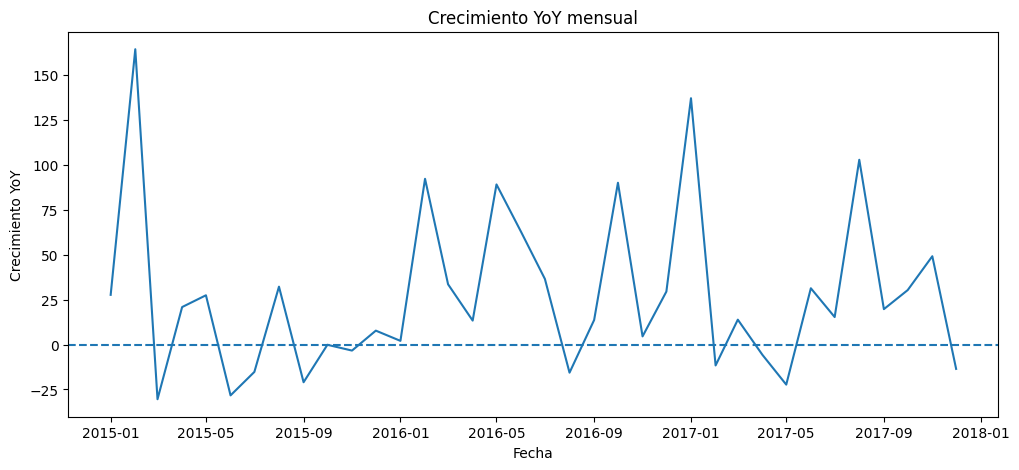

In [ ]:
#Crecimiento YoY mensual
plt.figure(figsize=(12,5))

plt.plot(df_clean.index, df_clean["revenue_YoY_pct"])

plt.axhline(0, linestyle="--")

plt.title("Crecimiento YoY mensual")
plt.xlabel("Fecha")
plt.ylabel("Crecimiento YoY")

plt.show()

Por medio del gráfico anterior se logra visualizar el comportamiento de los cambios en el ingreso a lo largo del periodo.

Se observa que la mayoría de los meses se ha logrado un crecimiento, lo cual significa que en el largo plazo se ha establecido una tendencia a la alza.

Y nuevamente se muestra un comportamiento bastante inestable, con múltiples valores superiores al 100%.

Por lo tanto, se usará `current_revenue` como serie objetivo y trataría el comportamiento YoY como información complementaria.

---

####Visualización de los ingresos mensuales

Text(0, 0.5, 'Ingresos')

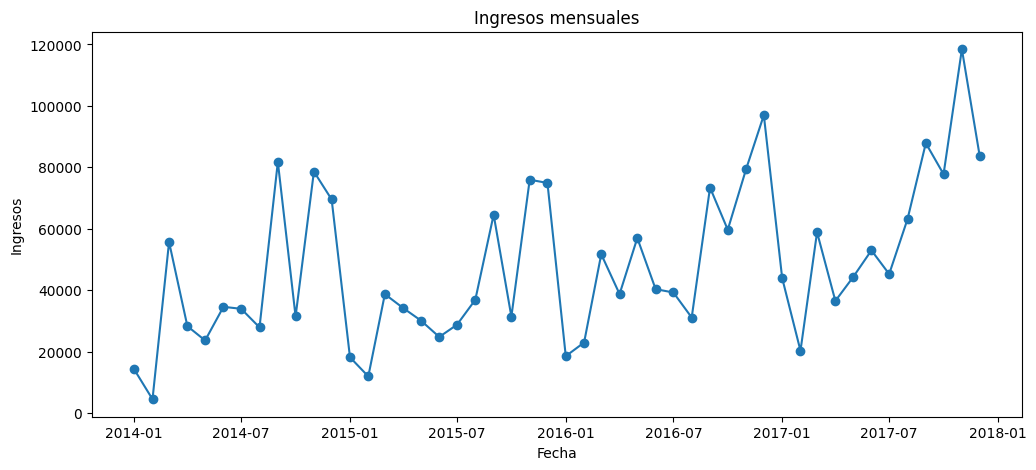

In [ ]:
#Ingresos mensuales
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df_clean.index, df_clean["current_revenue"], marker="o")

ax.set_title("Ingresos mensuales")
ax.set_xlabel("Fecha")
ax.set_ylabel("Ingresos")

Al observar las ventas mensuales en este formato, se logra apreciar una tendencia a la alza en las ventas, formando bajos más altos y altos más altos.

Además, se puede observar un comportamiento estacional, con una visible caída de los ingresos al inicio de cada año, mientras que a finales de año se alcanza constantemente un nuevo record de ventas mensuales.

---

####Creación de variable 'month'

Debido a que los datos de crecimiento YoY no son útiles para la construcción de un pronóstico confiable y estable, se utilizarán los datos de ventas de cada mes correspondiendo con el mismo periodo del año anterior, para de esta forma generar una tasa de crecimiento que capture la estacionalidad.

Para ello se deberá de volver a generar una columna con el mes de cada periodo.

In [ ]:
#Creación de columna 'month'
df_clean['month'] = df_clean.index.month

df_clean.head()

,current_revenue,revenue_YoY_pct,month
date,,,
2014-01-01,14236.895,NaN,1
2014-02-01,4519.892,NaN,2
2014-03-01,55691.009,NaN,3
2014-04-01,28295.345,NaN,4
2014-05-01,23648.287,NaN,5


---

###Análisis de propiedades

En este apartado se realizarán los análisis correspondientes de la serie de tiempo para posteriormente evaluar los parámetros de los modelos de pronóstico.

####Análisis de tendencia

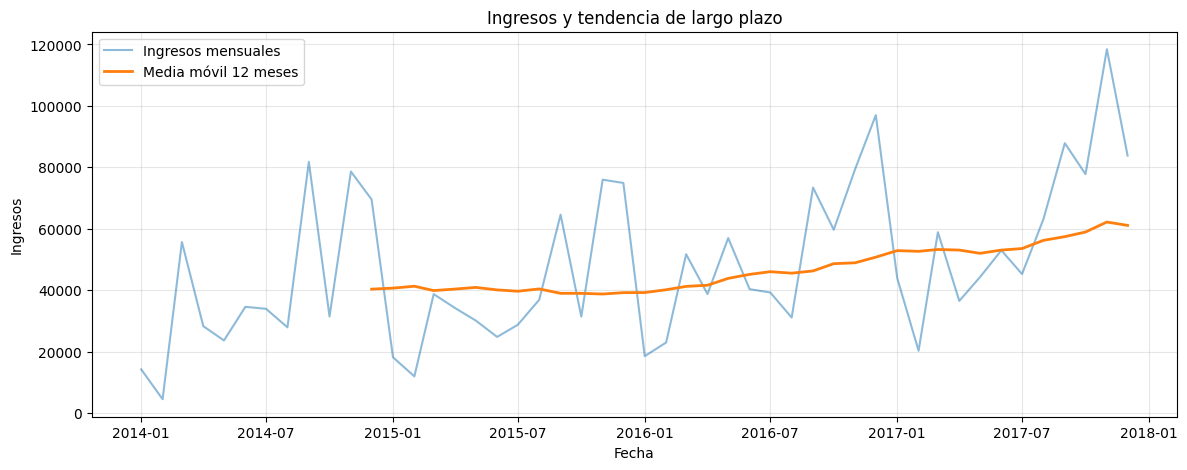

In [ ]:
#Media móvil a 12 ruedas
df_clean["revenue_ma_12"] = (df_clean["current_revenue"].rolling(12).mean())

#Serie de ingresos y media móvil
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_clean.index,df_clean["current_revenue"],alpha=0.5,label="Ingresos mensuales")
ax.plot(df_clean.index,df_clean["revenue_ma_12"],linewidth=2,label="Media móvil 12 meses")

#Gráfico
ax.set_title("Ingresos y tendencia de largo plazo")
ax.set_xlabel("Fecha")
ax.set_ylabel("Ingresos")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

Por medio de la visualización de una media móvil es posible observar de manera clara la presencia de una tendencia marcada hacia la alza, la cual muestra señales de aumento en el ritmo de crecimiento debido a la exponencialidad del crecimiento.

---

####Análisis de estacionalidad

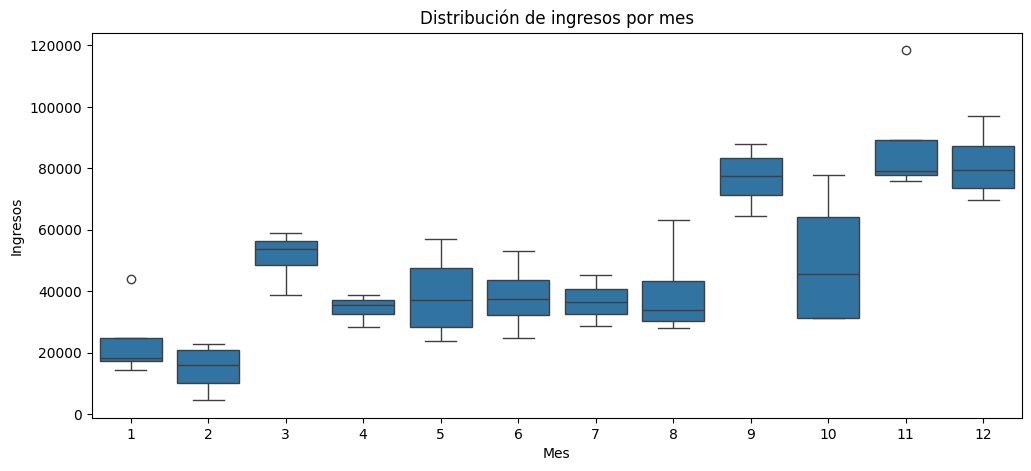

In [ ]:
#Box-plot de ingresos
plt.figure(figsize=(12, 5))

sns.boxplot(data=df_clean, x="month", y="current_revenue")

plt.title("Distribución de ingresos por mes")
plt.xlabel("Mes")
plt.ylabel("Ingresos")

plt.show()

Por medio del gráfico de caja para cada mes se logra apreciar una tendencia a lo largo de los 4 años contemplados.

El valor de la mediana muestra un patrón consistente con el observado con el gráfico de ventas mensuales. Los meses de Enero y Febrero tienden a generar ingresos menores al resto del año, mientras que los meses de Septiembre, Noviembre y Diciembre tienden a ser meses de alta demanda donde las ventas se disparan.

En meses como Mayo, Agosto y Octubre se observa una dispersión bastante evidente en cuanto a los valores de sus ventas, lo que demuestra volatilidad y presencia de valores extremos que pueden afectar la estabilidad.

---

####Análisis de autocorrelación ACF

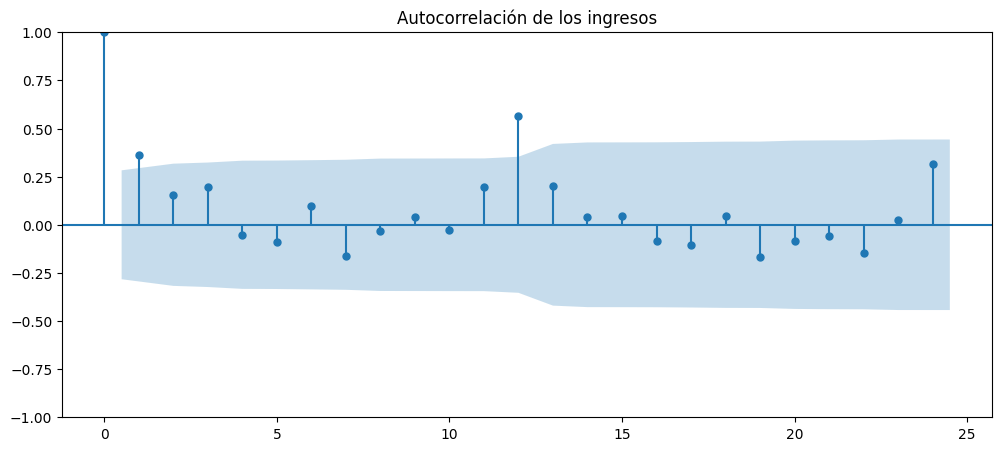

In [ ]:
#Gráfico ACF
fig, ax = plt.subplots(figsize=(12, 5))

plot_acf(df_clean["current_revenue"], lags=24, ax=ax)

ax.set_title("Autocorrelación de los ingresos")

plt.show()

En el gráfico se aprecia como el rezago 1 y el 12 muestran señales de autocorrelación, lo cual tiene sentido teniendo en cuenta la dependencia de un dato respecto al anterior, y a la relación de las ventas de un mes con las del mismo mes en el año anterior.

El rezago 24 se muestra dentro del nivel de confianza crítico, pero con un nivel de autocorrelación alto, lo cual hace sentido nuevamente debido a la estacionalidad.

In [ ]:
df_clean["current_revenue"].autocorr(lag=12)

np.float64(0.846909250893539)

Como evidencia contundente adicional, se observa una autocorrelación positiva y fuerte entre las ventas de un mes y su rezago 12, lo cual señala una fuerte estacionalidad anual.

---

###Pronósticos de crecimiento

A continuación, se muestra la contrucción y evaluación de los modelos a comparar.

El flujo metodológico para la construcción del pronóstico es el siguiente:

Modelo base (Seasonal Naïve) → Modelo Holt-Winters (ETS) → Modelo SARIMA → Comparación de modelos → Ingresos pronosticados

####Método Ingenuo Estacional (Seasonal Naïve)

El Método Ingenuo Estacional (Seasonal Naïve) es una técnica básica de pronóstico de series temporales que predice los valores futuros utilizando exactamente el valor observado en el mismo periodo de la temporada anterior.

El pronóstico para un periodo específico es igual al valor registrado en la última temporada equivalente.

• Fórmula general: $$(\hat{Y}_{t} = Y_{t-12})$$

Donde 12 es la longitud de la estacionalidad (por ejemplo, 12 para datos mensuales).

In [ ]:
#Generación de dataframe para evaluar pronósticos
test = df_clean.loc["2017"].copy()

#Pronóstivo con Naïve
test["forecast_naive"] = df_clean["current_revenue"].shift(12).loc["2017"]

#Evaluación de pronósticos
mae_naive = mean_absolute_error(
    test["current_revenue"],test["forecast_naive"])

rmse_naive = np.sqrt(mean_squared_error(
    test["current_revenue"],test["forecast_naive"]))

mape_naive = (np.mean(np.abs(
            (test["current_revenue"] - test["forecast_naive"])
            / test["current_revenue"])) * 100)

print(f"MAE:  {mae_naive:,.2f}")
print(f"RMSE: {rmse_naive:,.2f}")
print(f"MAPE: {mape_naive:.2f}%")

MAE:  15,467.89
RMSE: 18,985.70
MAPE: 24.52%


Los pronósticos bajo la asunción simple de Naïve muestran errores medios bastante elavados. No es necesariamente un mal resultado considerando la volatilidad de tus ingresos, pero deja bastante margen para intentar mejorar el pronóstico.

Aunque la autocorrelación en lag 12 es muy alta (0.84), el mismo mes del año anterior todavía presenta errores considerables (del 24.52% según el MAPE).

Esto sugiere que existe una estructura estacional fuerte, pero también hay cambios en el nivel y la tendencia de los ingresos entre años. Por eso tiene sentido probar un modelo que combine los niveles, la tendencia y la estacionalidad.

---

####Holt-Winters (ETS)

El método de Holt-Winters, también conocido como suavizamiento exponencial triple, es un algoritmo estadístico utilizado para realizar pronósticos en series de tiempo que presentan tendencia y estacionalidad.

1. Nivel (α - Alfa): Es la base o valor promedio actual de la serie desestacionalizada.
2. Tendencia (β - Beta): Controla el ritmo de cambio, indicando si los datos tienden a subir o bajar a lo largo del tiempo.
3. Estacionalidad (γ - Gamma): Modela los ciclos repetitivos (como el aumento de ventas en Navidad o el consumo de energía en verano).
Nota: Los coeficientes α, β y γ toman valores entre 0 y 1. Un valor más alto da mayor peso a los datos más recientes.


Especificaciones a utilizar:
- ETS aditivo
- ETS multiplicativo
- ETS con tendencia
- ETS sin tendencia

(ETS significa Error, Trend and Seasonality, o Error, Tendencia y Estacionalidad).

#####Modelo aditivo

In [ ]:
#Establecer datos de entrenamiento y de prueba
train = df_clean.loc[:'2016-12-01', 'current_revenue']
test = df_clean.loc['2017-01-01':, 'current_revenue']

#Modelo Holt-Winters aditivo
model_ets = ExponentialSmoothing(train,trend="add",seasonal="add",seasonal_periods=12)

fit_ets = model_ets.fit()

forecast_ets = fit_ets.forecast(12)

#Evaluación de pronóstico
mae_ets = mean_absolute_error(test, forecast_ets)

rmse_ets = np.sqrt(mean_squared_error(test, forecast_ets))

mape_ets = (np.mean(np.abs((test - forecast_ets) / test)) * 100)

print(f"MAE:  {mae_ets:,.2f}")
print(f"RMSE: {rmse_ets:,.2f}")
print(f"MAPE: {mape_ets:.2f}%")

MAE:  11,453.63
RMSE: 12,541.40
MAPE: 22.59%


El modelo muestra una mejora respecto al modelo base de Naïve, con el error cuadrático teniendo una disminución de 18,985.70 a 12,541.40.

Además, el porcentaje de error promedio absoluto mejora levemente a 22.59%, cuando previamente mostró un valor de 24.52%.

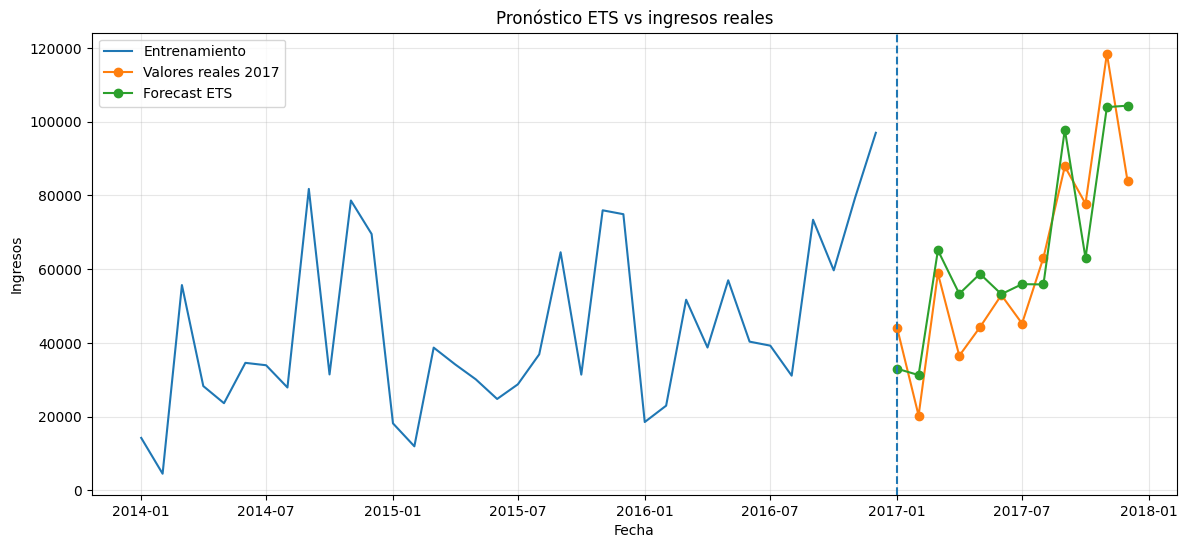

In [ ]:
#Visualización de pronósticos vs datos de 2017
plt.figure(figsize=(14, 6))

#Datos de test
plt.plot(train.index,train,label="Entrenamiento")

#Valores de 2017
plt.plot(test.index,test,label="Valores reales 2017",marker="o")

#Pronóstico de 2017
plt.plot(forecast_ets.index,forecast_ets,label="Forecast ETS",marker="o")

plt.axvline(x=pd.Timestamp("2017-01-01"),linestyle="--")

plt.title("Pronóstico ETS vs ingresos reales")
plt.xlabel("Fecha")
plt.ylabel("Ingresos")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

Con el gráfico se puede verificar el ajuste de los pronósticos, con la línea verde mostrándose bastante cercana al movimiento de la línea naranja, aunque aún tiene problemas para estimar los cambios en ingresos del segundo trimestre.

---

#####Modelo multiplicativo

In [ ]:
#Modelo Holt-Winters multiplicativo
model_ets_mul = ExponentialSmoothing(
    train,trend="add",seasonal="mul",seasonal_periods=12)

fit_ets_mul = model_ets_mul.fit()

forecast_ets_mul = fit_ets_mul.forecast(12)

#Evaluación de modelo
mae_ets_mul = mean_absolute_error(test, forecast_ets_mul)

rmse_ets_mul = np.sqrt(mean_squared_error(test, forecast_ets_mul))

mape_ets_mul = (np.mean(np.abs(
    (test - forecast_ets_mul) / test)) * 100)

print(f"MAE:  {mae_ets_mul:,.2f}")
print(f"RMSE: {rmse_ets_mul:,.2f}")
print(f"MAPE: {mape_ets_mul:.2f}%")

MAE:  12,431.80
RMSE: 16,384.39
MAPE: 20.77%


Al utilizar un error y una estacionalidad multiplicativa en el modelo ETS, el error absoluto promedio y el error absoluto promedio al cuadrado aumentan respecto al modelo aditivo.

Por otro lado, el error promedio en porcentaje muestra una diferencia menor, con un 20.77%. Esto es interesante porque indica que, relativamente al tamaño de cada observación, el modelo multiplicativo se comporta mejor.

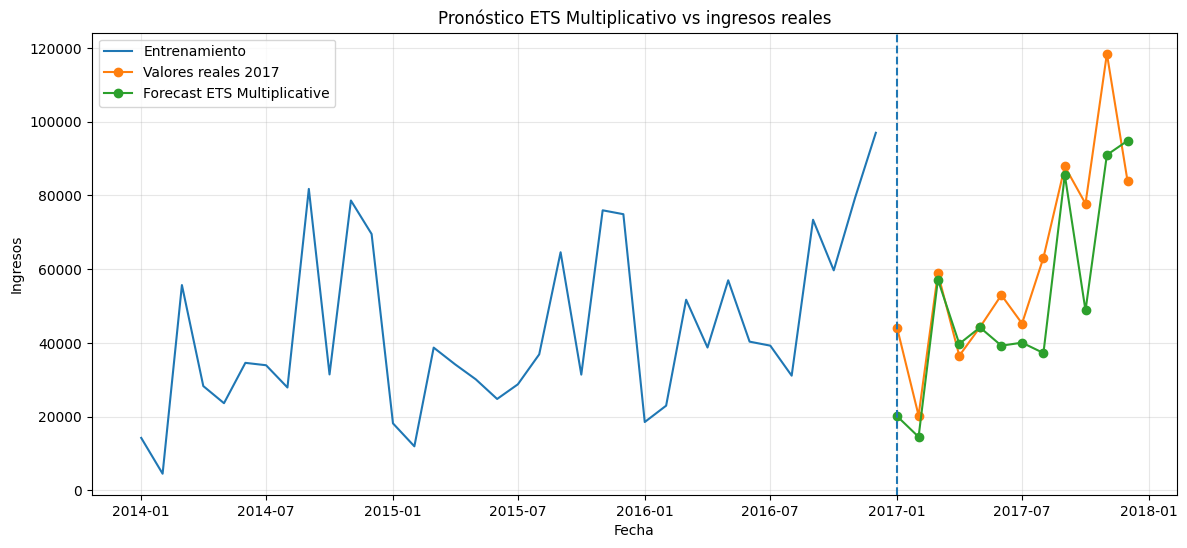

In [ ]:
#Visualización de pronósticos vs datos de 2017
plt.figure(figsize=(14, 6))

#Datos de test
plt.plot(train.index,train,label="Entrenamiento")

#Valores de 2017
plt.plot(test.index,test,label="Valores reales 2017",marker="o")

#Pronóstico de 2017
plt.plot(forecast_ets_mul.index,forecast_ets_mul,label="Forecast ETS Multiplicative",marker="o")

plt.axvline(x=pd.Timestamp("2017-01-01"),linestyle="--")

plt.title("Pronóstico ETS Multiplicativo vs ingresos reales")
plt.xlabel("Fecha")
plt.ylabel("Ingresos")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

En el caso del modelo multiplicativo se observa como el ajuste varía en ciertos casos. Por ejemplo, durante el segundo trimestre se aprecia como le es nuevamente difícil capturar los cambios para el año 2017, aunque esta vez subestima los ingresos en vez de sobrestimarlos como sucedió en el caso del modelo con error y estacionalidad multiplicativa.

Además, en los periodos de más alto ingreso (Noviembre y Diciembre) se nota un error mayor en la precisión de los pronósticos respecto al modelo aditivo.

---

####Modelo SARIMA

El modelo SARIMA (Seasonal Autoregressive Integrated Moving Average) es una extensión del modelo ARIMA que permite predecir series temporales con comportamientos estacionales (patrones que se repiten en intervalos fijos, como ventas navideñas o consumo de energía por clima).

Estructura del modelo:

$$(p, d, q) × (P, D, Q)ₛ$$

- Parte no estacional (p, d, q):
	- p: Orden autorregresivo (dependencia de los valores pasados).
	- d: Grado de diferenciación (para quitar tendencias y lograr estacionariedad).
	- q: Orden de media móvil (dependencia de errores de pronóstico pasados).
- Parte estacional (P, D, Q)ₛ:
	- P: Orden autorregresivo estacional.
	- D: Grado de diferenciación estacional.
	- Q: Orden de media móvil estacional.
	- s: Longitud del período estacional (ej. s = 12 para datos mensuales)


#####Pruebas ADF y KPSS

In [ ]:
#Pruebas ADF y KPSS
adf_result = adfuller(df_clean['current_revenue'])

kpss_result = kpss(df_clean['current_revenue'], regression="ct", nlags="auto")

print("ADF")
print(f"Statistic: {adf_result[0]:.4f}")
print(f"p-value:   {adf_result[1]:.4f}")

print("\nKPSS")
print(f"Statistic: {kpss_result[0]:.4f}")
print(f"p-value:   {kpss_result[1]:.4f}")

ADF
Statistic: -4.4938
p-value:   0.0002

KPSS
Statistic: 0.0743
p-value:   0.1000


/tmp/ipykernel_451/1037100458.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(df_clean['current_revenue'])
/tmp/ipykernel_451/1037100458.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(df_clean['current_revenue'], regression="ct", nlags="auto")
/tmp/ipykernel_451/1037100458.py:4: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior w

Los resultados de las pruebas son consistentes, señalando que la serie carece de raíz unitaria, por lo cual es estacionaria. Cabe destacar que con solo 48 observaciones las pruebas tienen poca potencia, pero para motivos de este trabajo se simplificarían los parámetros de la prueba.

Según este resultado la serie no requiere diferenciación para modelar por SARIMA, por lo cual los modelos a probar serán de tipo $(p,0,q)$$(P,D,Q)_{12}$.

Para definir $D$ es necesario analizar el comportamiento de la serie y las funciones ACF/PACF.

---

#####ACF y PACF

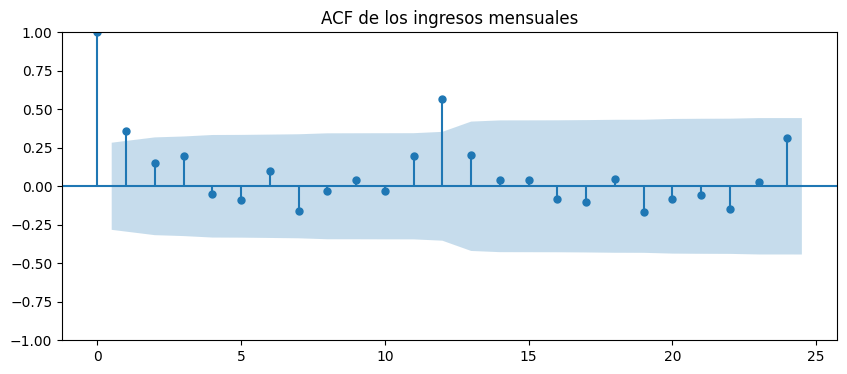

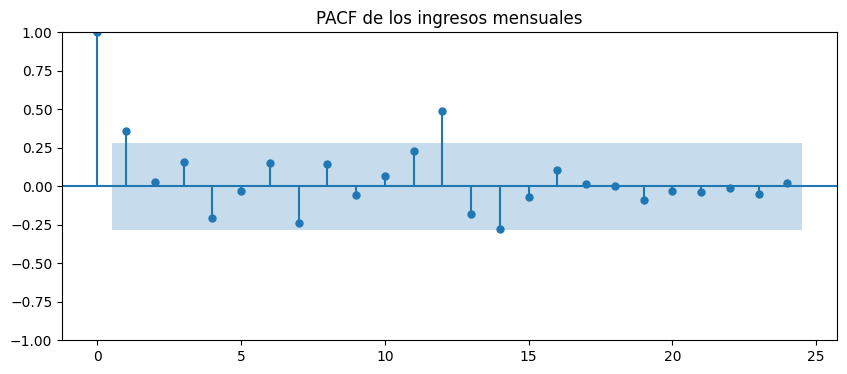

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))

plot_acf(df_clean['current_revenue'],lags=24,ax=ax)

ax.set_title("ACF de los ingresos mensuales")
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))

plot_pacf(df_clean['current_revenue'],lags=24,ax=ax,method="ywm")

ax.set_title("PACF de los ingresos mensuales")
plt.show()

ACF y PACF muestran autocorrelación por encima del nivel crítico de confianza en los rezagos 1 y 12.

Dichos rezagos corresponden al primer rezago inmediato de cada valor y al rezago de hace 12 meses respectivamente. Esto es consistente con las propiedades de series de tiempo estacionalidad anual.

---

#####Estimaciones iniciales

Según la información obtenida hasta el momento:
- Estacionariedad: $d=0$
- Periodicidad: $s=12$
- Estacionalidad: fuerte, debido a ACF(12) = 0.84

No tendría sentido comenzar con un modelo excesivamente complejo.

Modelos iniciales:

$$SARIMA(1,0,1)(1,0,1)_{12}$$

$$SARIMA(1,0,0)(1,0,0)_{12}$$

$$SARIMA(0,0,1)(0,0,1)_{12}$$

$$SARIMA(1,0,1)(1,0,0)_{12}$$

$$SARIMA(1,0,1)(0,0,1)_{12}$$

El mejor modelo no se definirá únicamente por AIC/BIC, ya que al igual que se hizo con ETS, lo importante será el desempeño sobre 2017.

In [ ]:
#Familia de modelos iniciales
modelos = {"SARIMA(1,0,1)(1,0,1,12)": ((1, 0, 1), (1, 0, 1, 12)),
           "SARIMA(1,0,1)(1,0,0,12)": ((1, 0, 0), (1, 0, 0, 12)),
           "SARIMA(0,0,1)(0,0,1,12)": ((0, 0, 1), (0, 0, 1, 12)),
           "SARIMA(1,0,1)(1,0,0,12)": ((1, 0, 1), (1, 0, 0, 12)),
           "SARIMA(1,0,1)(0,0,1,12)": ((1, 0, 1), (0, 0, 1, 12))}


resultados = []

#Estimación de modelos
for nombre, (order, seasonal_order) in modelos.items():

    modelo = SARIMAX(
        train,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    resultado = modelo.fit(disp=False)

    resultados.append({"modelo": nombre,"AIC": resultado.aic,"BIC": resultado.bic})

resultados_df = pd.DataFrame(resultados).sort_values("AIC")

resultados_df

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


,modelo,AIC,BIC
0,"SARIMA(1,0,1)(1,0,1,12)",497.800425,503.255638
3,"SARIMA(1,0,1)(0,0,1,12)",498.550575,502.914745
1,"SARIMA(1,0,1)(1,0,0,12)",518.337293,522.879270
2,"SARIMA(0,0,1)(0,0,1,12)",528.644390,531.917517


Resultados:
- AIC: gana $SARIMA(1,0,1)(1,0,1,12)$.
- BIC: gana ligeramente $SARIMA(1,0,1)(0,0,1,12)$.
- La diferencia de AIC entre los dos primeros es apenas 0.75.
- La diferencia de BIC es apenas 0.34.

No se posee evidencia suficiente para decir que el modelo más complejo sea claramente superior. De hecho, dado que solo hay 48 observaciones, el modelo
$SARIMA(1,0,1)(0,0,1,12)$ puede ser preferible por su parsimonia, ya que consigue prácticamente el mismo AIC/BIC con un parámetro menos.

Para aclarar el panorama, previamente hay que determinar si los modelos captan la autocorrelación por completo o si queda autocorrelación no capturada en los residuos.

---

#####Prueba Ljung-Box (residuos)

In [ ]:
#SARIMA(1,0,1)(1,0,1,12)
modelo_sarima = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(1, 0, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

resultado_sarima = modelo_sarima.fit(disp=False)

#Prueba Ljung-Box
ljung_box = acorr_ljungbox(
    resultado_sarima.resid,
    lags=[12, 24],
    return_df=True
)

ljung_box

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


,lb_stat,lb_pvalue
12,9.046309,0.698970
24,13.349933,0.959998


In [ ]:
#SARIMA(1,0,1)(0,0,1,12)
modelo_sarima = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(0, 0, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

resultado_sarima = modelo_sarima.fit(disp=False)

#Prueba Ljung-Box
ljung_box = acorr_ljungbox(
    resultado_sarima.resid,
    lags=[12, 24],
    return_df=True
)

ljung_box

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


,lb_stat,lb_pvalue
12,7.745903,0.804659
24,18.348532,0.785781


Los modelos SARIMA evaluados lograron capturar adecuadamente la estructura de autocorrelación de la serie. El análisis de los residuos mediante la prueba de Ljung-Box no identificó autocorrelación serial significativa en los rezagos evaluados, por lo que los residuos pueden considerarse consistentes con un proceso de ruido blanco. Esto indica que ambos modelos representan adecuadamente la dinámica temporal de los ingresos y permite avanzar a la comparación de su capacidad predictiva fuera de muestra.

Y al volver a la comparativa entre modelos, por ahora los resultados son bastante razonables y apuntan a que $SARIMA(1,0,1)(0,0,1,12)$ es un candidato especialmente interesante por su equilibrio entre ajuste y parsimonia.

---

#####Backtesting

Si bien los criterios de selección hasta ahora se inclinan por el modelo $SARIMA(1,0,1)(0,0,1,12)$, lo cierto es que para hacer una comparativa contundente es necesario evaluar la precisión de las predicciones fuera de muestra. Para ello se usará el periodo de prueba de 2017.

In [ ]:
#Modelos finales establecidos
modelos_sarima = {"SARIMA(1,0,1)(1,0,1,12)": ((1, 0, 1), (1, 0, 1, 12)),
                  "SARIMA(1,0,1)(0,0,1,12)": ((1, 0, 1), (0, 0, 1, 12))}

pronosticos_sarima = {}

#Generación de modelos
for nombre, (order, seasonal_order) in modelos_sarima.items():

    modelo = SARIMAX(
        train,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    resultado = modelo.fit(disp=False)

    pronostico = resultado.get_forecast(steps=12).predicted_mean

    pronosticos_sarima[nombre] = pronostico

#Convertir serie test a DataFrame
comparacion_sarima = test.to_frame(name="current_revenue").copy()

for nombre, pronostico in pronosticos_sarima.items():
    comparacion_sarima[nombre] = pronostico.values

comparacion_sarima

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


,current_revenue,"SARIMA(1,0,1)(1,0,1,12)","SARIMA(1,0,1)(0,0,1,12)"
date,,,
2017-01-01,43971.3740,46823.916760,77892.880092
2017-02-01,20301.1334,48855.508852,84874.739032
2017-03-01,58872.3528,70462.342068,104748.953835
2017-04-01,36521.5361,60488.470485,100037.258651
2017-05-01,44261.1102,72262.839749,115339.205910
2017-06-01,52981.7257,59989.667612,115182.859382
2017-07-01,45264.4160,59042.399866,119283.015679
2017-08-01,63120.8880,53482.835483,118052.454149
2017-09-01,87866.6520,84580.630178,147223.787828


In [ ]:
#Evaluación de pronósticos
metricas_sarima = []

for nombre in modelos_sarima:

    y_real = comparacion_sarima["current_revenue"]
    y_pred = comparacion_sarima[nombre]

    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    mape = np.mean(np.abs((y_real - y_pred) / y_real)) * 100

    metricas_sarima.append({
        "Modelo": nombre,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

metricas_sarima = pd.DataFrame(metricas_sarima)

metricas_sarima

,Modelo,MAE,RMSE,MAPE
0,"SARIMA(1,0,1)(1,0,1,12)",15058.698081,17913.126533,34.216362
1,"SARIMA(1,0,1)(0,0,1,12)",61410.177795,63272.006357,123.524838


---

####Comparación entre modelos

In [ ]:
#Comparación global entre modelos
comparacion_modelos = pd.DataFrame([
    {
        "Modelo": "Naïve estacional",
        "MAE": 15467.89,
        "RMSE": 18985.70,
        "MAPE": 24.52
    },
    {
        "Modelo": "ETS aditivo",
        "MAE": 11453.63,
        "RMSE": 12541.40,
        "MAPE": 22.59
    },
    {
        "Modelo": "ETS multiplicativo",
        "MAE": 12431.80,
        "RMSE": 16384.39,
        "MAPE": 20.77
    }
])

comparacion_modelos = pd.concat(
    [comparacion_modelos, metricas_sarima],
    ignore_index=True
).sort_values("RMSE")

comparacion_modelos

,Modelo,MAE,RMSE,MAPE
1,ETS aditivo,11453.630000,12541.400000,22.590000
2,ETS multiplicativo,12431.800000,16384.390000,20.770000
3,"SARIMA(1,0,1)(1,0,1,12)",15058.698081,17913.126533,34.216362
0,Naïve estacional,15467.890000,18985.700000,24.520000
4,"SARIMA(1,0,1)(0,0,1,12)",61410.177795,63272.006357,123.524838


La evaluación fuera de muestra mostró que el modelo ETS aditivo presentó el mejor desempeño global entre los modelos evaluados, alcanzando un MAE de 11,453.63 y un RMSE de 12,541.40. Aunque el ETS multiplicativo obtuvo el menor MAPE (20.77%), el ETS aditivo presentó menores errores absolutos y una menor penalización de los errores de mayor magnitud, por lo que resulta más adecuado para el pronóstico de ingresos.

Los modelos SARIMA, a pesar de capturar adecuadamente la autocorrelación de la serie y presentar residuos sin autocorrelación serial significativa, no superaron a los modelos ETS en términos de capacidad predictiva. En particular, el SARIMA(1,0,1)(1,0,1,12) obtuvo un MAE de 15,058.70 y un RMSE de 17,913.13, mientras que el SARIMA(1,0,1)(0,0,1,12) presentó un desempeño considerablemente inferior.

En consecuencia, se selecciona el modelo ETS aditivo como modelo final, priorizando su menor error absoluto y su mejor desempeño en la predicción fuera de muestra.

---

####Ingresos pronosticados 2018

El siguiente paso natural es muy importante, el cual consiste en tomar el modelo ETS aditivo ganador, reentrenarlo utilizando los 48 meses completos (2014–2017) y generar el pronóstico de los siguientes 12 meses. Ahí se daría por terminado propiamente la fase de forecasting.

In [ ]:
#Entrenamiento de modelo final
modelo_final = ExponentialSmoothing(df_clean['current_revenue'] ,trend="add",
                                    seasonal="add", seasonal_periods=12)

resultado_final = modelo_final.fit(optimized=True)

print(resultado_final.summary())

                       ExponentialSmoothing Model Results                       
Dep. Variable:          current_revenue   No. Observations:                   48
Model:             ExponentialSmoothing   SSE                     3842809319.375
Optimized:                         True   AIC                            905.517
Trend:                         Additive   BIC                            935.456
Seasonal:                      Additive   AICC                           929.103
Seasonal Periods:                    12   Date:                 Wed, 14 Oct 2026
Box-Cox:                          False   Time:                         04:55:14
Box-Cox Coeff.:                    None                                         
                          coeff                 code              optimized      
---------------------------------------------------------------------------------
smoothing_level               0.1417637                alpha                 True
smoothing_trend          

In [ ]:
#Pronóstico de 2018
pronostico_12m = resultado_final.forecast(12)

pronostico_12m = pronostico_12m.to_frame(name="forecast_revenue")

pronostico_12m

,forecast_revenue
2018-01-01,49691.584907
2018-02-01,41836.947430
2018-03-01,74880.052264
2018-04-01,61539.961431
2018-05-01,68503.507548
2018-06-01,65399.980241
2018-07-01,67081.660762
2018-08-01,66682.553451
2018-09-01,108143.478601
2018-10-01,77833.129499


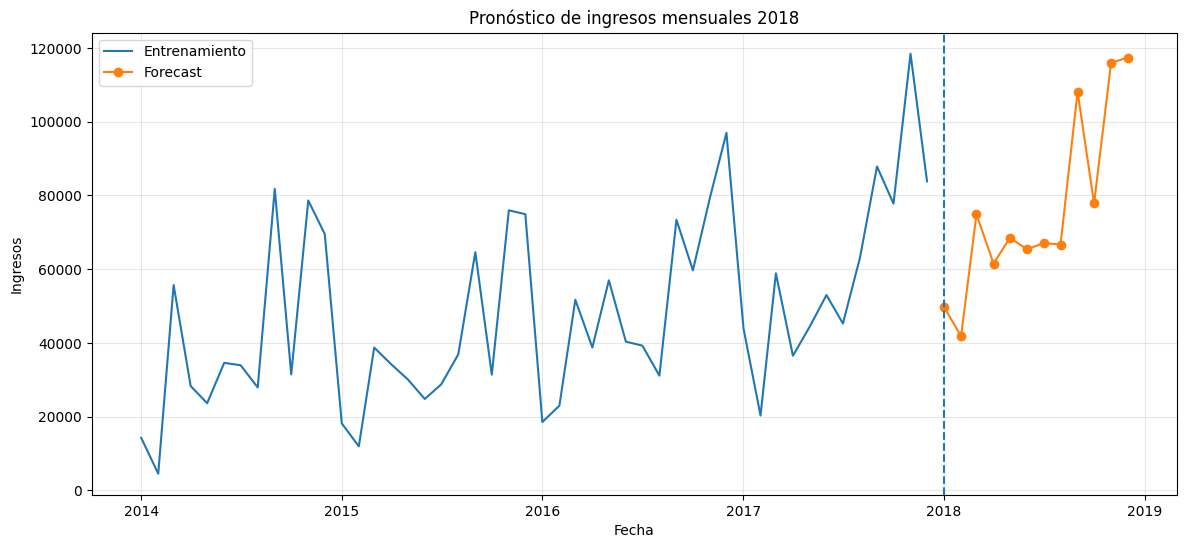

In [ ]:
#Datos de entrenamiento
revenue = df_clean.loc[:'2017-12-01', 'current_revenue']

#Visualización de pronósticos de 2018
plt.figure(figsize=(14, 6))

#Datos de entrenamiento 2014-2017
plt.plot(revenue.index,revenue,label="Entrenamiento")

#Pronóstico de 2018
plt.plot(pronostico_12m.index,pronostico_12m,label="Forecast",marker="o")

plt.axvline(x=pd.Timestamp("2018-01-01"),linestyle="--")

plt.title("Pronóstico de ingresos mensuales 2018")
plt.xlabel("Fecha")
plt.ylabel("Ingresos")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [1]:
#Pronóstico de ingresos anual
expected_revenue = round(pronostico_12m['forecast_revenue'].sum(),2)

print(f'Pronóstico de ingresos 2018: ${expected_revenue}')

NameError: name 'pronostico_12m' is not defined

Según muestra el pronóstico, se espera un patrón estacional similar a los años previos a lo largo del año 2018, con un total de ventas esperado de $914,968.06

En los meses correspondientes al tercer trimestre, se muestra un comportamiento muy estable y sin volatilidad, aunque hay que recordar que el modelo actual tiene dificultades para pronosticar estos periodos fuera de muestra.

En cuanto a los meses de más alta demanda, se espera que se mantenga el crecimiento de ventas YoY en el mes de Septiembre. Sin embargo, el mes de Noviembre muestra una expectativa a la baja derivado de la actual tendencia que se ha experimentado en los últimos cuatro años, aunque en el mes de Diciembre el pronóstico apunta a que no se experimentará una caída en ventas como se acostumbra.

In [ ]:
#Ventas 2014-2017
anual_summary_short = anual_summary[['year', 'total_revenue']]

#Ventas 2018
sales_2018 = pd.DataFrame({'year': [2018], 'total_revenue': [expected_revenue]})

#Juntar ventas actuales con pronóstico 2018
guidance = pd.concat([anual_summary_short, sales_2018], ignore_index=True)

#Agregar crecimiento YoY%
guidance['YoY%'] = (((guidance['total_revenue']) /
 (guidance['total_revenue'].shift(1))) - 1) * 100

guidance

,year,total_revenue,YoY%
0,2014,484247.4981,NaN
1,2015,470532.5090,-2.832227
2,2016,609205.5980,29.471521
3,2017,733215.2552,20.355962
4,2018,914968.0600,24.788465


El pronóstico anual muestra un crecimiento esperado del 24.79% anual, lo cual es superior al ritmo de crecimiento experimentado en 2017, pero menor al crecimiento record de  2016.